# 03 · ARGUS crew baselines: checking the TypeScript analytics with Python

**Question.** Do the baselines and anomaly detectors that the ARGUS server stores (spec 05 §5) match an independent computation in pandas/statsmodels? What does the circadian structure of the wearable data look like?

**Data:** `npm run data:export` from the ARGUS database. ⚠️ This is **simulated** data from the assumed sensor kit (`scripts/simulate-wearables.ts`, spec 05 §4), not astronaut data.

**Method:**
- Recompute the hour-of-day medians and compare them with the stored `baselines`.
- STL decomposition (statsmodels) of hourly heart rate into trend, daily cycle and residual.
- Review the anomaly table.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from argus_analysis.data import export, REFERENCE
from argus_analysis.ai import summarize
pd.set_option('display.width', 140)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': 0.3})

In [2]:
hr = export('minute_heart_rate', parse_dates=['ts'])
base = export('baselines')
daily = export('daily_metrics', parse_dates=['day'])
anom = export('anomalies', parse_dates=['ts_start', 'ts_end'])
who = 'crew-lindqvist'
print(hr.astronaut_id.value_counts())

astronaut_id
crew-lindqvist    20096
crew-okafor       20096
crew-chen         20094
crew-vance        20085
Name: count, dtype: int64


In [3]:
# 1. Validate stored hour-of-day medians against pandas.
h = hr[hr.astronaut_id == who].copy(); h['hour'] = h.ts.dt.hour
mine = h.groupby('hour').value.median().rename('pandas_median')
stored = base[(base.astronaut_id == who) & (base.metric_id == 'heart_rate') & (base.kind == 'hour_of_day')].set_index('hour')['median'].rename('stored_median')
cmp = pd.concat([mine, stored], axis=1).dropna()
cmp['diff'] = (cmp.pandas_median - cmp.stored_median).abs()
print('max |difference| =', cmp['diff'].max(), 'bpm  (small differences come from the export window vs the job window)')
cmp.head(24).T

max |difference| = 0.0 bpm  (small differences come from the export window vs the job window)


hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
pandas_median,78.0,70.0,70.0,70.0,70.0,71.0,70.0,70.0,80.0,86.0,...,87.0,87.0,86.0,85.0,97.0,84.0,82.0,81.0,80.0,79.0
stored_median,78.0,70.0,70.0,70.0,70.0,71.0,70.0,70.0,80.0,86.0,...,87.0,87.0,86.0,85.0,97.0,84.0,82.0,81.0,80.0,79.0
diff,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


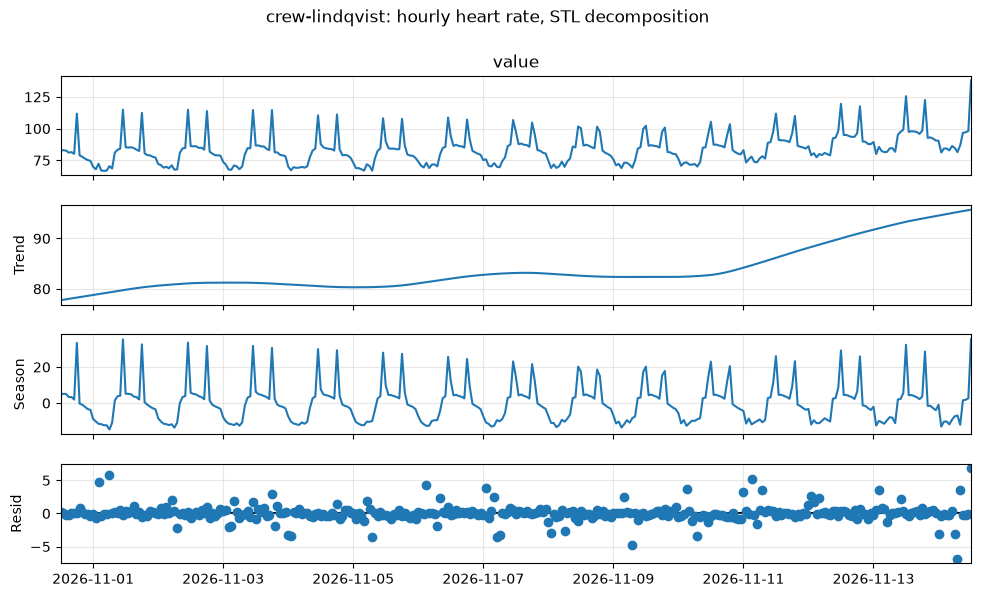

Trend change over the window: +15.8 bpm; daily-cycle amplitude: 50.2 bpm


In [4]:
# 2. STL decomposition of hourly heart rate (period = 24 h).
from statsmodels.tsa.seasonal import STL
s = h.set_index('ts').value.resample('1h').mean().interpolate()
res = STL(s, period=24, robust=True).fit()
fig = res.plot(); fig.set_size_inches(10, 6); fig.suptitle(f'{who}: hourly heart rate, STL decomposition', y=1.02)
plt.show()
print(f"Trend change over the window: {res.trend.iloc[-24:].mean() - res.trend.iloc[:24].mean():+.1f} bpm; "
      f"daily-cycle amplitude: {res.seasonal.max() - res.seasonal.min():.1f} bpm")

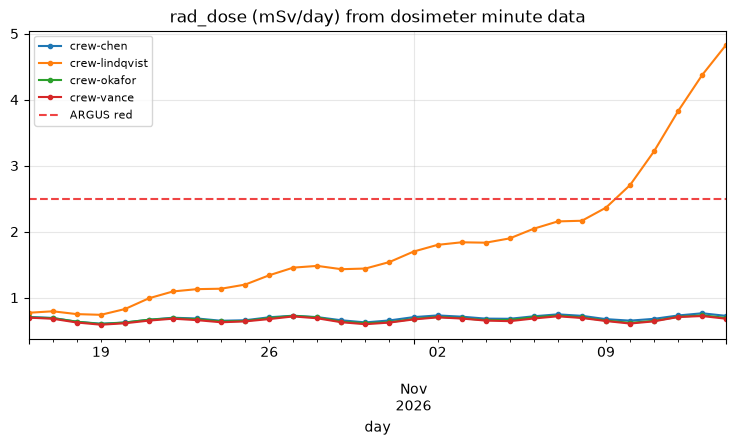

In [5]:
# 3. Daily radiation dose per astronaut against the personal pre-flight baseline.
rad = daily[daily.metric_id == 'rad_dose'].pivot(index='day', columns='astronaut_id', values='value')
ax = rad.plot(marker='.', title='rad_dose (mSv/day) from dosimeter minute data'); ax.axhline(2.5, color='#ef4444', ls='--', label='ARGUS red'); ax.legend(fontsize=8)
plt.show()

In [6]:
# 4. Anomalies found by the server job (informational: they never change triage).
anom.groupby(['astronaut_id', 'detector', 'severity']).size().unstack(fill_value=0)

severity                 drifting  watch
astronaut_id   detector                 
crew-chen      cusum            7      0
               ewma             7      3
               robust_z         4      1
crew-lindqvist cusum            9      0
               ewma             9      2
               robust_z         9      1
crew-okafor    cusum            9      0
               ewma             9      2
               robust_z         4      0
crew-vance     cusum            0      1
               ewma             0      1
               robust_z         5      0

### Findings
- If the stored hour-of-day medians match pandas to within the export window, the server implementation is independently confirmed.
- STL separates a slow **trend** (scenario drift) from the **daily cycle**. That is why ARGUS compares minute heart rate with the same hour of day (`hour_of_day` baseline) rather than with one daily mean.
- Possible next step: replace the hour-of-day median with an STL-based expected value once the model is promoted from this notebook into `shared/analytics/` (spec 05 §7, "notebooks are never the source of truth").